# Explorare Preprocessing — Vezi ce face fiecare pas pe imaginile tale

**Scop:** Înainte să decidem definitiv pipeline-ul de preprocessing, să vedem cu ochii noștri pe câteva imagini din fiecare sursă (HAM, BCN, MSK):

1. Cum arată imaginile **raw**
2. Ce face **black border crop**
3. Ce face **Shades of Gray** color constancy  
4. Cum arată după **resize + center crop**

La fiecare pas avem statistici (color means, histograms) ca să vedem efectul cantitativ.

**Notă:** Acest notebook e DOAR pentru explorare/decizii. Nu produce niciun output care să fie folosit de pașii următori. E un tool de inspecție vizuală.

---

## 1. Setup

In [1]:
# Mount Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

BASE_DIR = '/content/drive/MyDrive/Thesis'
TRAIN_POOL_PATH = f'{BASE_DIR}/pipeline_outputs/step1/train_pool.csv'

df = pd.read_csv(TRAIN_POOL_PATH)
print(f"Imagini disponibile: {len(df):,}")
print(f"Surse: {df['source'].value_counts().to_dict()}")

Mounted at /content/drive
Imagini disponibile: 20,299
Surse: {'BCN_20000': 9969, 'HAM10000': 8042, 'other': 1637, 'MSK': 651}


## 2. Funcțiile de preprocessing (versiuni Python pure)

Astea sunt versiunile pe care le-am discutat. Le păstrăm aici ca referință, le folosim pe imagini reale mai jos.

In [2]:
def crop_black_border(img, threshold=10):
    """
    Crop black border pe baza unei binarizări simple.
    img: numpy array [H, W, 3] uint8
    Returns: cropped image
    """
    gray = np.mean(img, axis=2)
    mask = gray > threshold

    if not mask.any():
        return img

    rows = np.any(mask, axis=1)
    cols = np.any(mask, axis=0)
    rmin, rmax = np.where(rows)[0][[0, -1]]
    cmin, cmax = np.where(cols)[0][[0, -1]]

    return img[rmin:rmax+1, cmin:cmax+1]


def shades_of_gray(img, power=6):
    """
    Shades of Gray color constancy (Finlayson & Trezzi, 2004).
    Folosit de câștigătorii ISIC 2018-2019.
    """
    img_float = img.astype(np.float32)
    img_power = np.power(img_float, power)
    rgb_vec = np.power(np.mean(img_power, axis=(0, 1)), 1/power)
    rgb_norm = np.sqrt(np.sum(rgb_vec ** 2))
    if rgb_norm == 0:
        return img
    rgb_vec = rgb_vec / rgb_norm
    rgb_vec = 1 / (rgb_vec * np.sqrt(3))
    img_corrected = img_float * rgb_vec
    return np.clip(img_corrected, 0, 255).astype(np.uint8)


def resize_with_aspect(img, target=256):
    """Resize cu păstrare aspect ratio: latura mai scurtă → target."""
    h, w = img.shape[:2]
    if h < w:
        new_h = target
        new_w = int(w * target / h)
    else:
        new_w = target
        new_h = int(h * target / w)
    return cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)


def center_crop(img, size=256):
    """Center crop la size×size."""
    h, w = img.shape[:2]
    start_h = max(0, (h - size) // 2)
    start_w = max(0, (w - size) // 2)
    return img[start_h:start_h+size, start_w:start_w+size]


def full_pipeline(img, target_size=256):
    """Pipeline-ul complet offline."""
    img1 = crop_black_border(img)
    img2 = shades_of_gray(img1)
    img3 = resize_with_aspect(img2, target=target_size)
    img4 = center_crop(img3, size=target_size)
    return img1, img2, img3, img4

print('Funcții definite.')

Funcții definite.


## 3. Sample-uri din fiecare sursă

Selectăm câte 2 imagini din fiecare sursă. Vedem dimensiuni și sursa originală.

In [3]:
def get_samples_per_source(df, n_per_source=2, seed=42):
    """Selectează n imagini per sursă."""
    samples = []
    for src in ['HAM10000', 'BCN_20000', 'MSK', 'other']:
        sub = df[df['source'] == src]
        if len(sub) == 0:
            continue
        chosen = sub.sample(min(n_per_source, len(sub)), random_state=seed)
        samples.append(chosen)
    return pd.concat(samples).reset_index(drop=True)


samples = get_samples_per_source(df, n_per_source=2)
print(f"Total samples selectate: {len(samples)}")
print(samples[['image_id', 'source', 'dx']].to_string())

Total samples selectate: 8
                   image_id     source   dx
0              ISIC_0034274   HAM10000   nv
1              ISIC_0025222   HAM10000  bkl
2              ISIC_0054826  BCN_20000   nv
3              ISIC_0057266  BCN_20000  bcc
4  ISIC_0014527_downsampled        MSK  mel
5  ISIC_0013355_downsampled        MSK   nv
6              ISIC_0010075      other   nv
7  ISIC_0016005_downsampled      other   nv


## 4. Vedem imaginile raw

Doar pentru a vedea cum arată — dimensiuni diferite, posibile black borders, color casts diferite per sursă.

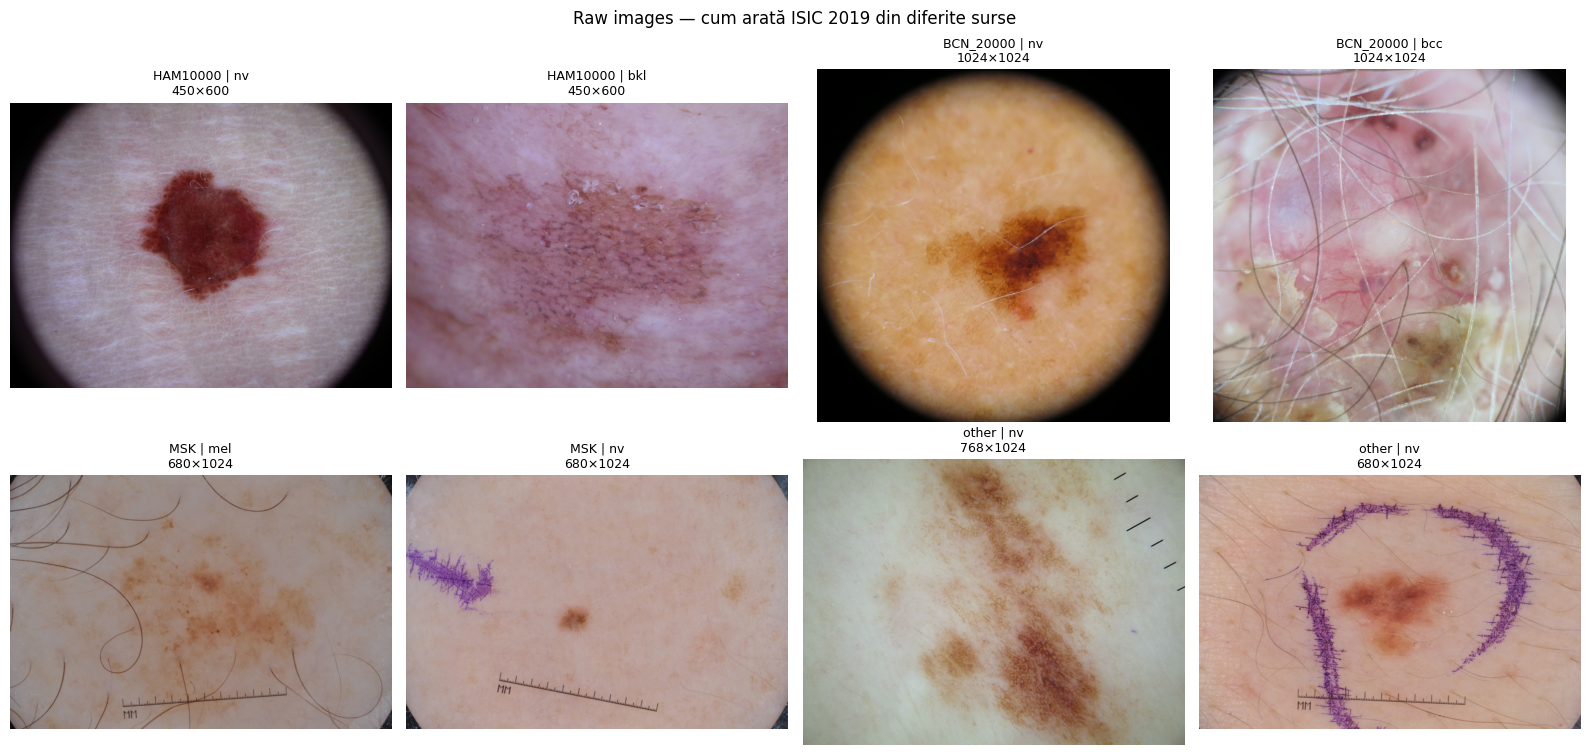

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, samples.iterrows()):
    img = np.array(Image.open(row['image_path']))
    ax.imshow(img)
    ax.set_title(f"{row['source']} | {row['dx']}\n{img.shape[0]}×{img.shape[1]}", fontsize=9)
    ax.axis('off')

plt.suptitle('Raw images — cum arată ISIC 2019 din diferite surse', fontsize=12)
plt.tight_layout()
plt.show()

## 5. Black border crop — vezi efectul

Pentru fiecare imagine: înainte vs după crop. Cifra "reduction" arată cât % din imagine a fost margine neagră eliminată.

In [5]:
fig, axes = plt.subplots(len(samples), 2, figsize=(10, 4*len(samples)))

for i, (_, row) in enumerate(samples.iterrows()):
    img = np.array(Image.open(row['image_path']))
    img_cropped = crop_black_border(img)

    orig_pixels = img.shape[0] * img.shape[1]
    cropped_pixels = img_cropped.shape[0] * img_cropped.shape[1]
    reduction = 100 * (1 - cropped_pixels / orig_pixels)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"RAW — {row['source']} | {row['dx']}\n{img.shape[0]}×{img.shape[1]}", fontsize=9)
    axes[i, 0].axis('off')

    axes[i, 1].imshow(img_cropped)
    axes[i, 1].set_title(f"CROP — {img_cropped.shape[0]}×{img_cropped.shape[1]}\n(reduction: {reduction:.1f}%)", fontsize=9)
    axes[i, 1].axis('off')

plt.suptitle('Black border crop — efect per sursă', fontsize=12)
plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

Searching for images with visible black borders (reduction > 5%)...


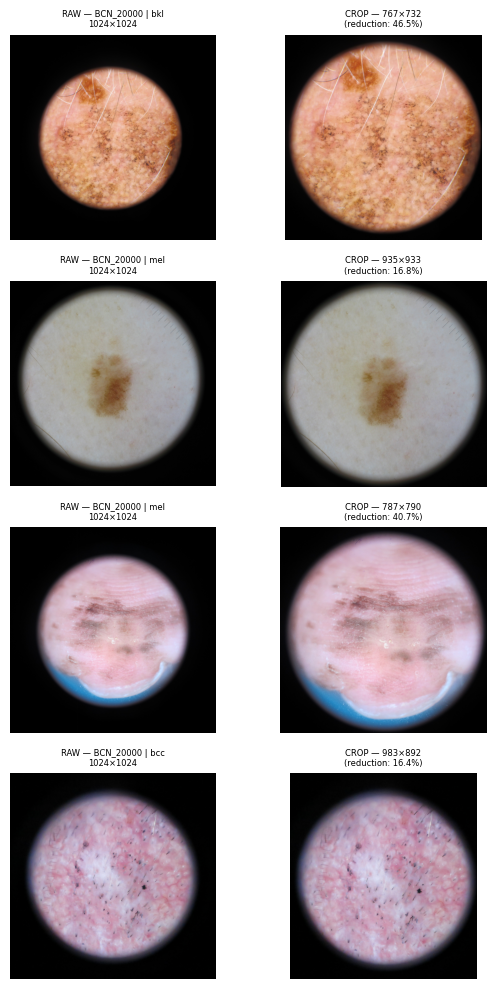

In [16]:
def find_images_with_black_borders(df, n=4, threshold=5.0, max_search=200, seed=42):
    """Searches for images that have at least `threshold`% black border reduction."""
    found = []
    search_pool = df.sample(min(max_search, len(df)), random_state=seed)

    for _, row in search_pool.iterrows():
        if len(found) >= n:
            break
        try:
            img = np.array(Image.open(row['image_path']))
            img_cropped = crop_black_border(img)
            orig_pixels = img.shape[0] * img.shape[1]
            cropped_pixels = img_cropped.shape[0] * img_cropped.shape[1]
            reduction = 100 * (1 - cropped_pixels / orig_pixels)

            if reduction > threshold:
                found.append((row, img, img_cropped, reduction))
        except Exception:
            continue
    return found

print("Searching for images with visible black borders (reduction > 5%)...")
examples = find_images_with_black_borders(df, n=4, threshold=5.0)

if examples:
    # Reduced figsize to make images smaller
    fig, axes = plt.subplots(len(examples), 2, figsize=(6, 2.5*len(examples)))
    if len(examples) == 1:
        axes = axes.reshape(1, 2)

    for i, (row, img, img_cropped, reduction) in enumerate(examples):
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"RAW — {row['source']} | {row['dx']}\n{img.shape[0]}×{img.shape[1]}", fontsize=6)
        axes[i, 0].axis('off')

        axes[i, 1].imshow(img_cropped)
        axes[i, 1].set_title(f"CROP — {img_cropped.shape[0]}×{img_cropped.shape[1]}\n(reduction: {reduction:.1f}%)", fontsize=6)
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Could not find images with significant black borders in the search pool.")


## 6. Shades of Gray color constancy — vezi efectul

Compară imaginile după crop, dar înainte vs după SoG. **Cele mai relevante cifre sunt RGB means** — la final ar trebui să fie aproximativ egale.

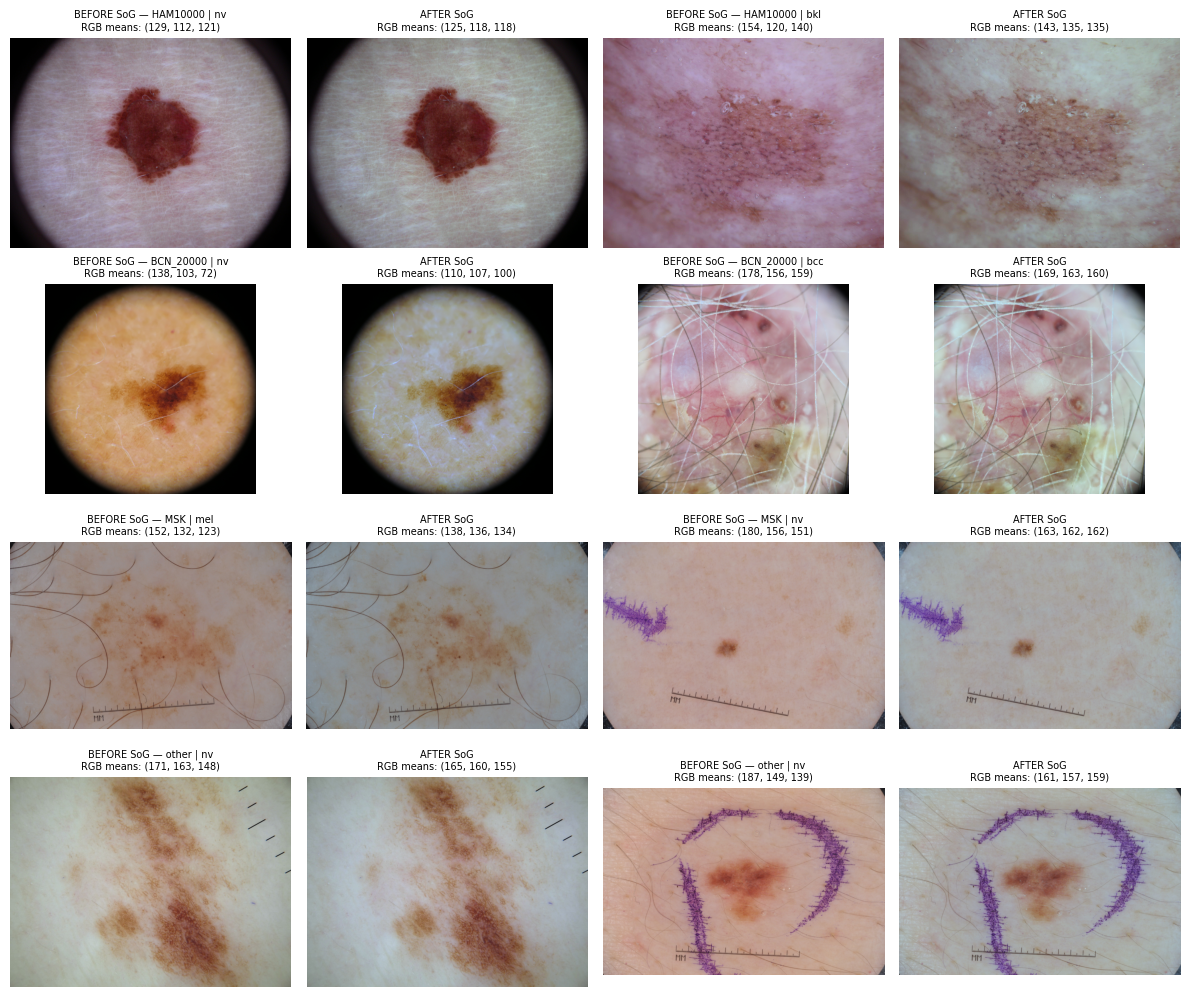

In [17]:
fig, axes = plt.subplots(4, 4, figsize=(12, 10))

for i, (_, row) in enumerate(samples.iterrows()):
    r = i // 2
    c = (i % 2) * 2

    img = np.array(Image.open(row['image_path']))
    img_cropped = crop_black_border(img)
    img_sog = shades_of_gray(img_cropped)

    rgb_before = img_cropped.mean(axis=(0,1))
    rgb_after = img_sog.mean(axis=(0,1))

    axes[r, c].imshow(img_cropped)
    axes[r, c].set_title(f"BEFORE SoG — {row['source']} | {row['dx']}\n"
                         f"RGB means: ({rgb_before[0]:.0f}, {rgb_before[1]:.0f}, {rgb_before[2]:.0f})",
                         fontsize=7)
    axes[r, c].axis('off')

    axes[r, c+1].imshow(img_sog)
    axes[r, c+1].set_title(f"AFTER SoG\n"
                         f"RGB means: ({rgb_after[0]:.0f}, {rgb_after[1]:.0f}, {rgb_after[2]:.0f})",
                         fontsize=7)
    axes[r, c+1].axis('off')

plt.tight_layout()
plt.show()


## 7. Statistici cantitative: color means per sursă

Pentru a vedea **dacă există într-adevăr domain shift** între surse — calculăm media RGB pe câte 50 imagini per sursă, înainte și după SoG.

Calculez statistici color per sursă...
(asta poate dura 1-2 minute)

  Procesez HAM10000...
  Procesez BCN_20000...
  Procesez MSK...


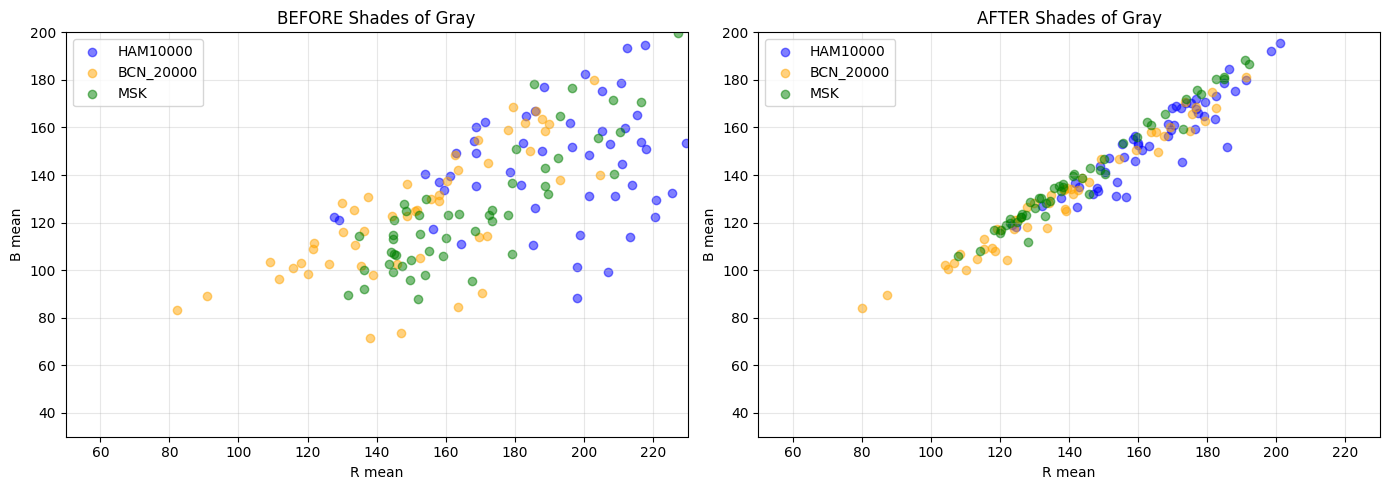


Mean RGB per sursă (50 samples):
  HAM10000:
    Before SoG: R=190.8  G=138.4  B=143.8
    After SoG:  R=164.2  G=156.2  B=154.3
  BCN_20000:
    Before SoG: R=151.5  G=130.7  B=123.6
    After SoG:  R=138.8  G=134.9  B=131.7
  MSK:
    Before SoG: R=168.6  G=139.4  B=126.7
    After SoG:  R=147.3  G=145.0  B=143.4


In [18]:
def compute_color_stats(df_subset, n_samples=50, apply_sog=False, seed=42):
    """Calculează RGB means pe un sample."""
    sample = df_subset.sample(min(n_samples, len(df_subset)), random_state=seed)
    rgb_means = []
    for _, row in sample.iterrows():
        try:
            img = np.array(Image.open(row['image_path']))
            img = crop_black_border(img)
            if apply_sog:
                img = shades_of_gray(img)
            rgb_means.append(img.mean(axis=(0,1)))
        except Exception as e:
            continue
    return np.array(rgb_means)

print("Calculez statistici color per sursă...")
print("(asta poate dura 1-2 minute)")
print()

stats = {}
for src in ['HAM10000', 'BCN_20000', 'MSK']:
    sub = df[df['source'] == src]
    if len(sub) == 0:
        continue
    print(f"  Procesez {src}...")
    stats[src] = {
        'before': compute_color_stats(sub, apply_sog=False),
        'after': compute_color_stats(sub, apply_sog=True),
    }

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, key, title in zip(axes, ['before', 'after'],
                           ['BEFORE Shades of Gray', 'AFTER Shades of Gray']):
    for src, color in zip(stats.keys(), ['blue', 'orange', 'green']):
        means = stats[src][key]
        ax.scatter(means[:, 0], means[:, 2], alpha=0.5, label=src, color=color)
    ax.set_xlabel('R mean')
    ax.set_ylabel('B mean')
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xlim(50, 230)
    ax.set_ylim(30, 200)

plt.tight_layout()
plt.show()

# Print numerice
print()
print("Mean RGB per sursă (50 samples):")
for src in stats:
    b = stats[src]['before'].mean(axis=0)
    a = stats[src]['after'].mean(axis=0)
    print(f"  {src}:")
    print(f"    Before SoG: R={b[0]:.1f}  G={b[1]:.1f}  B={b[2]:.1f}")
    print(f"    After SoG:  R={a[0]:.1f}  G={a[1]:.1f}  B={a[2]:.1f}")

**Cum interpretezi graficele:**

- **Înainte SoG**: dacă vezi clusterele HAM, BCN, MSK în zone DIFERITE → există domain shift prin culoare → SoG e necesar
- **După SoG**: dacă clusterele se suprapun mai mult → SoG funcționează → confirmă necesitatea
- **Numerele "Mean RGB per sursă"**: dacă HAM are R=145 și BCN are R=160 înainte de SoG, dar amândoi ajung la R=140 după, e dovada cantitativă că SoG normalizează.

## 8. Pipeline complet — toți pașii vizualizați

Pentru o imagine: raw → crop → SoG → resize → center crop. Vedem fiecare pas.

In [19]:
def show_full_pipeline(df, source, n=2, target_size=256):
    sub = df[df['source'] == source]
    if len(sub) == 0:
        print(f"Nu există imagini pentru sursa {source}")
        return

    samples = sub.sample(min(n, len(sub)), random_state=42)

    fig, axes = plt.subplots(n, 5, figsize=(20, 4*n))
    if n == 1:
        axes = axes.reshape(1, -1)

    for i, (_, row) in enumerate(samples.iterrows()):
        img = np.array(Image.open(row['image_path']))
        crop, sog, resized, final = full_pipeline(img, target_size)

        for ax, im, title in zip(
            axes[i],
            [img, crop, sog, resized, final],
            [f'Raw\n{img.shape[0]}×{img.shape[1]}',
             f'Crop border\n{crop.shape[0]}×{crop.shape[1]}',
             f'+ SoG\n{sog.shape[0]}×{sog.shape[1]}',
             f'+ Resize\n{resized.shape[0]}×{resized.shape[1]}',
             f'+ Center crop\n{final.shape[0]}×{final.shape[1]}']
        ):
            ax.imshow(im)
            ax.set_title(title, fontsize=9)
            ax.axis('off')
    plt.tight_layout()
    plt.show()


# Pentru fiecare sursă
for src in ['HAM10000', 'BCN_20000', 'MSK']:
    show_full_pipeline(df, src, n=2)

Output hidden; open in https://colab.research.google.com to view.

## 9. Concluzie

După ce vezi rezultatele, decide:

- [x] **Black border crop e necesar?** Verifică pe BCN — dacă "reduction %" e des >5%, da. Dacă e des <2%, opțional.
- [x] **Shades of Gray e necesar?** Verifică graficele — dacă clusterele sursă sunt diferite înainte și se suprapun după, da.
- [x] **224 vs 256 ca target_size?** După rulare, încearcă target=224 și 256, vezi dacă diferă vizibil.

Dacă toate trei sunt confirmate, mergem la PASUL 4 cu pipeline-ul complet (crop + SoG + resize 256 + center crop).